# Proyecto P04-SEG-01: Modelo de Segmentación (K-Means) y Clasificación (Random Forest) de Clientes Mayoristas
**Cliente:** Distribuidora Alimentos del Pacífico S.A. (Gerencia de Operaciones y Logística)  
**Asignatura:** SCY1102 — Gestión de Proyectos de Datos (Evaluación Parcial N°5)  
**Equipo 7:** Eduardo Rodríguez (Director), Benjamín Luengo (Ing. de Datos / EDA) y Diego Pinto (Científico de Datos / Líder Técnico)  
**Marco Metodológico:** CRISP-DM (Fases 2 a 5: Comprensión, Preparación, Modelado y Evaluación)  

---
### Arquitectura del Entregable Funcional (K-Means + Random Forest)
Dado que los registros históricos de facturación (`440` clientes, `8` variables) no cuentan con etiquetas previas de segmentos logísticos, el sistema implementa exclusivamente **dos modelos complementarios**:
1. **Etapa 1 — Segmentación No Supervisada con `KMeans` (`EDT 1.4.2`–`1.4.3`, Req. `R.4` y `R.5`):** Evalúa el algoritmo **K-Means** (`init='k-means++'`, `random_state=42`) para $k \in \{2, 3, 4, 5, 6\}$ mediante Inercia (Método del Codo), Coeficiente de Silueta e Índice Davies-Bouldin, seleccionando $k=4$ para identificar **4 perfiles mayoristas homogéneos**.
2. **Etapa 2 — Clasificación Supervisada con `RandomForestClassifier` (`EDT 1.4.4`, Req. `R.9`):** Entrena y valida un modelo **Random Forest** sobre los 4 perfiles descubiertos por K-Means, permitiendo:
   - Validar estadísticamente la separabilidad de los segmentos (`Accuracy: 96,59%` y `F1-Macro: 0,9670` en prueba).
   - Identificar qué categorías de productos impulsan cada perfil (*Feature Importance*).
   - Clasificar nuevos clientes mayoristas con **probabilidad de pertenencia (`predict_proba`)** y acción logística sugerida.

## 1. Configuración del Entorno e Ingesta de Datos (EDT 1.2.1 — Req. R.1 y R.12)

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import (
    silhouette_score, davies_bouldin_score,
    accuracy_score, f1_score, classification_report, confusion_matrix
)
from sklearn.decomposition import PCA

# Configuración global de reproducibilidad y estilo gráfico
SEED = 42
np.random.seed(SEED)
plt.rcParams['figure.dpi'] = 120
sns.set_theme(style="whitegrid", palette="muted")

df = pd.read_csv("Wholesale customers data.csv")

print(f"Dataset cargado correctamente: {df.shape[0]} filas x {df.shape[1]} columnas")
display(df.head())

Dataset cargado correctamente: 440 filas x 8 columnas


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


## 2. Auditoría de Calidad y Análisis Exploratorio de Datos — EDA (EDT 1.2.2 y 1.3 — Req. R.2)

In [3]:
spend_cols = ['Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicassen']

# 2.1 Verificación de integridad (nulos y duplicados)
print("Valores nulos por columna:")
print(df.isnull().sum())
print(f"\nRegistros duplicados exactos: {df.duplicated().sum()}")

# 2.2 Distribución por Canal (1=Horeca, 2=Retail) y Región
print("\nDistribución por Channel (%):")
print((df['Channel'].value_counts(normalize=True) * 100).round(2))
print("\nDistribución por Region:")
print(df['Region'].value_counts())

# 2.3 Estadísticas descriptivas, asimetría y outliers IQR (Riesgo R01)
desc = df[spend_cols].describe().T
desc['skewness'] = df[spend_cols].skew()
Q1 = df[spend_cols].quantile(0.25)
Q3 = df[spend_cols].quantile(0.75)
IQR = Q3 - Q1
desc['outliers_IQR'] = ((df[spend_cols] < (Q1 - 1.5 * IQR)) | (df[spend_cols] > (Q3 + 1.5 * IQR))).sum()

print("\nDiagnóstico estadístico de gasto por categoría:")
display(desc[['count', 'mean', '50%', 'std', 'max', 'skewness', 'outliers_IQR']].round(2))

Valores nulos por columna:
Channel             0
Region              0
Fresh               0
Milk                0
Grocery             0
Frozen              0
Detergents_Paper    0
Delicassen          0
dtype: int64

Registros duplicados exactos: 0

Distribución por Channel (%):
Channel
1    67.73
2    32.27
Name: proportion, dtype: float64

Distribución por Region:
Region
3    316
1     77
2     47
Name: count, dtype: int64

Diagnóstico estadístico de gasto por categoría:


,count,mean,50%,std,max,skewness,outliers_IQR
Fresh,440.0,12000.30,8504.0,12647.33,112151.0,2.56,20
Milk,440.0,5796.27,3627.0,7380.38,73498.0,4.05,28
Grocery,440.0,7951.28,4755.5,9503.16,92780.0,3.59,24
Frozen,440.0,3071.93,1526.0,4854.67,60869.0,5.91,43
Detergents_Paper,440.0,2881.49,816.5,4767.85,40827.0,3.63,30
Delicassen,440.0,1524.87,965.5,2820.11,47943.0,11.15,27


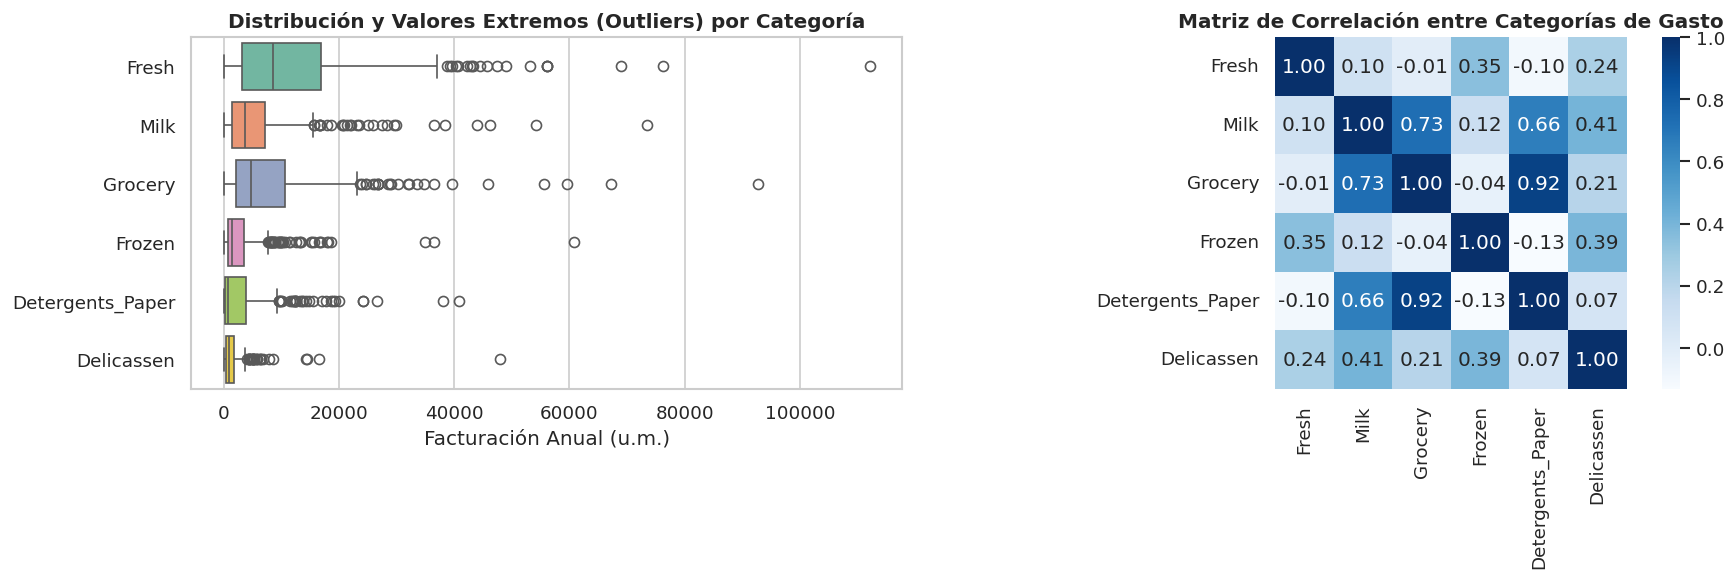

In [4]:
# 2.4 Visualización diagnóstica de outliers y correlaciones
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.boxplot(data=df[spend_cols], orient='h', ax=axes[0], palette='Set2')
axes[0].set_title('Distribución y Valores Extremos (Outliers) por Categoría', fontweight='bold')
axes[0].set_xlabel('Facturación Anual (u.m.)')

sns.heatmap(df[spend_cols].corr(), annot=True, fmt='.2f', cmap='Blues', square=True, ax=axes[1])
axes[1].set_title('Matriz de Correlación entre Categorías de Gasto', fontweight='bold')

plt.tight_layout()
plt.show()

## 3. Ingeniería de Características y Transformación Robusta (EDT 1.2.3–1.4.1 — Req. R.3)

In [5]:
# 3.1 Prueba Baseline con K-Means (sin tratar outliers ni proporciones de compra)
X_raw_scaled = StandardScaler().fit_transform(df[spend_cols])
km_baseline = KMeans(n_clusters=4, random_state=SEED, n_init=10).fit(X_raw_scaled)
dist_baseline = (pd.Series(km_baseline.labels_).value_counts(normalize=True) * 100).round(2)
print("Distribución Baseline K-Means (k=4) sin tratar outliers (%):")
print(dist_baseline)
print("-> Se activa el Quality Gate (R01/R03): concentración excesiva por efecto de clientes extremos.\n")

# 3.2 Ingeniería de características: Gasto Total y Mix Relativo por Categoría (Riesgo R02)
df_prep = df.copy()
df_prep['Total_Spend'] = df_prep[spend_cols].sum(axis=1)

share_cols = []
for col in spend_cols:
    col_share = f'Share_{col}'
    df_prep[col_share] = df_prep[col] / df_prep['Total_Spend']
    share_cols.append(col_share)

# 3.3 Transformación logarítmica ln(1+x) y escalamiento robusto (RobustScaler)
log_cols = []
for col in spend_cols:
    col_log = f'Log_{col}'
    df_prep[col_log] = np.log1p(df_prep[col])
    log_cols.append(col_log)

scaler_seg = RobustScaler()
X_log_scaled = scaler_seg.fit_transform(df_prep[log_cols])
X_share = df_prep[share_cols].values

# Matriz analítica para Etapa 1 (Segmentación K-Means)
X_seg = np.hstack([X_log_scaled, X_share * 2.0])
print(f"Matriz preparada para Segmentación K-Means: {X_seg.shape}")

Distribución Baseline K-Means (k=4) sin tratar outliers (%):
1    71.59
0    25.00
2     2.27
3     1.14
Name: proportion, dtype: float64
-> Se activa el Quality Gate (R01/R03): concentración excesiva por efecto de clientes extremos.

Matriz preparada para Segmentación K-Means: (440, 12)


## 4. Etapa 1 — Segmentación No Supervisada con K-Means (EDT 1.4.2–1.4.3 — Req. R.4 y R.5)

Evaluación de K-Means por número de clústeres (k):


,Algoritmo,k,Inercia_WCSS,Coeficiente_Silueta,Indice_Davies_Bouldin
0,K-Means (k-means++),2,1289.3,0.2630,1.4870
1,K-Means (k-means++),3,1070.6,0.2386,1.3918
2,K-Means (k-means++),4,957.8,0.1897,1.4828
3,K-Means (k-means++),5,881.9,0.1825,1.5396
4,K-Means (k-means++),6,812.8,0.1813,1.5005


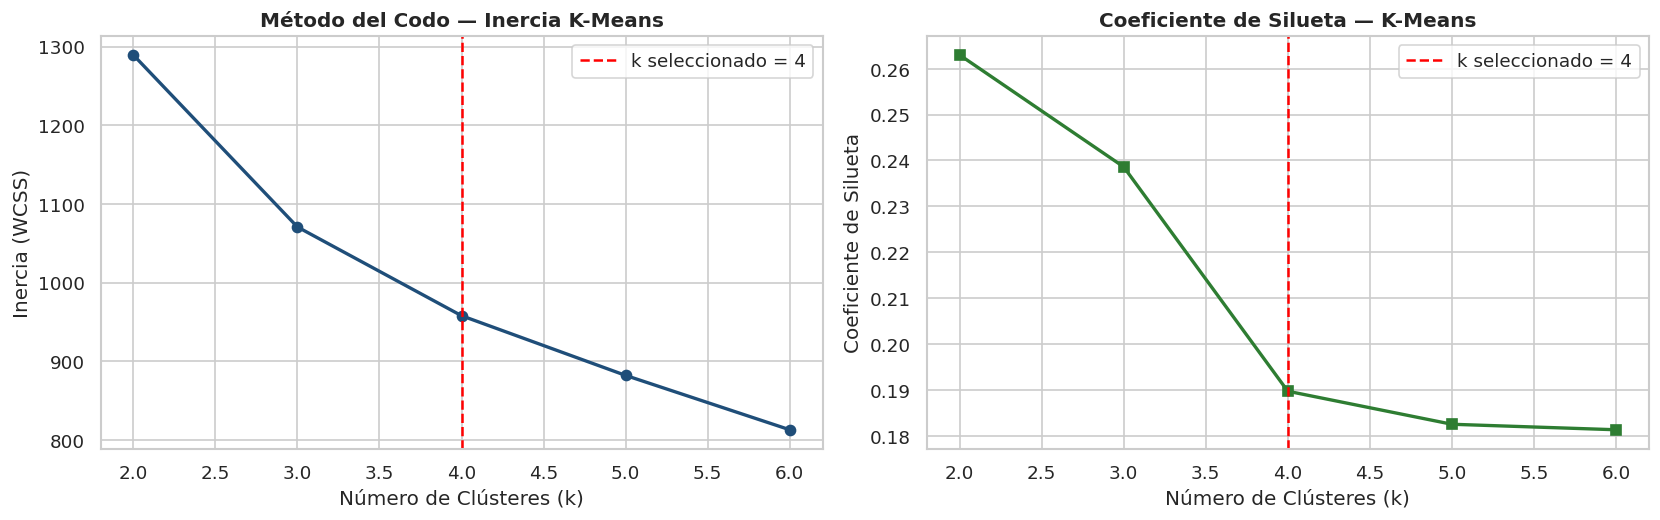

In [6]:
# Evaluación sistemática de K-Means para k = 2 hasta k = 6
resultados_kmeans = []

for k in range(2, 7):
    km = KMeans(n_clusters=k, init='k-means++', random_state=SEED, n_init=20)
    labels_km = km.fit_predict(X_seg)
    resultados_kmeans.append({
        'Algoritmo': 'K-Means (k-means++)',
        'k': k,
        'Inercia_WCSS': round(km.inertia_, 1),
        'Coeficiente_Silueta': round(silhouette_score(X_seg, labels_km), 4),
        'Indice_Davies_Bouldin': round(davies_bouldin_score(X_seg, labels_km), 4)
    })

df_res_kmeans = pd.DataFrame(resultados_kmeans)
print("Evaluación de K-Means por número de clústeres (k):")
display(df_res_kmeans)

# Visualización del Método del Codo (Inercia) y Coeficiente de Silueta para K-Means
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].plot(df_res_kmeans['k'], df_res_kmeans['Inercia_WCSS'], marker='o', linewidth=2, color='#1f4e79')
axes[0].axvline(4, color='red', linestyle='--', label='k seleccionado = 4')
axes[0].set_title('Método del Codo — Inercia K-Means', fontweight='bold')
axes[0].set_xlabel('Número de Clústeres (k)')
axes[0].set_ylabel('Inercia (WCSS)')
axes[0].legend()

axes[1].plot(df_res_kmeans['k'], df_res_kmeans['Coeficiente_Silueta'], marker='s', linewidth=2, color='#2e7d32')
axes[1].axvline(4, color='red', linestyle='--', label='k seleccionado = 4')
axes[1].set_title('Coeficiente de Silueta — K-Means', fontweight='bold')
axes[1].set_xlabel('Número de Clústeres (k)')
axes[1].set_ylabel('Coeficiente de Silueta')
axes[1].legend()

plt.tight_layout()
plt.show()

In [7]:
# Entrenamiento del modelo final de segmentación K-Means (k=4)
modelo_segmentacion = KMeans(n_clusters=4, init='k-means++', random_state=SEED, n_init=20)
df_prep['Cluster'] = modelo_segmentacion.fit_predict(X_seg)

nombres_perfiles = {
    0: 'P0: Horeca Frescos Alto Volumen',
    1: 'P1: Retail Conveniencia / Minimarkets',
    2: 'P2: Retail Supermercados Alto Volumen',
    3: 'P3: Horeca Estándar / Cafés y Rest.'
}
df_prep['Perfil_Negocio'] = df_prep['Cluster'].map(nombres_perfiles)

# Caracterización de los 4 perfiles mayoristas descubiertos por K-Means
resumen_perfiles = df_prep.groupby(['Cluster', 'Perfil_Negocio']).agg(
    Clientes=('Total_Spend', 'count'),
    Pct_Cartera=('Total_Spend', lambda x: round(len(x) / len(df_prep) * 100, 1)),
    Pct_Horeca=('Channel', lambda x: round((x == 1).mean() * 100, 1)),
    Fresh_Prom=('Fresh', 'mean'),
    Milk_Prom=('Milk', 'mean'),
    Grocery_Prom=('Grocery', 'mean'),
    Frozen_Prom=('Frozen', 'mean'),
    Detergents_Prom=('Detergents_Paper', 'mean'),
    Delicassen_Prom=('Delicassen', 'mean'),
    Gasto_Total_Prom=('Total_Spend', 'mean')
).round(1)

print("Caracterización comercial y logística de los 4 segmentos (K-Means k=4):")
display(resumen_perfiles)

Caracterización comercial y logística de los 4 segmentos (K-Means k=4):


,,Clientes,Pct_Cartera,Pct_Horeca,Fresh_Prom,Milk_Prom,Grocery_Prom,Frozen_Prom,Detergents_Prom,Delicassen_Prom,Gasto_Total_Prom
Cluster,Perfil_Negocio,,,,,,,,,,
0,P0: Horeca Frescos Alto Volumen,81,18.4,92.6,24447.2,4666.1,5259.2,8588.8,797.3,2973.9,46732.4
1,P1: Retail Conveniencia / Minimarkets,151,34.3,97.4,12116.3,1750.1,2275.5,2280.8,443.6,624.3,19490.5
2,P2: Retail Supermercados Alto Volumen,137,31.1,31.4,9745.3,10730.7,14153.4,1857.4,5915.2,2116.8,44518.7
3,P3: Horeca Estándar / Cafés y Rest.,71,16.1,46.5,1904.8,6169.6,11126.1,804.2,4590.4,644.9,25240.0


## 5. Etapa 2 — Modelo de Clasificación Supervisada con Random Forest (EDT 1.4.4 — Req. R.9)

In [8]:
# Definición de variables predictoras (X_clf) y variable objetivo (Cluster asignado por K-Means)
feature_cols_clf = spend_cols + ['Total_Spend'] + share_cols
X_clf = df_prep[feature_cols_clf]
y_clf = df_prep['Cluster']

# Partición estratificada 80% entrenamiento / 20% prueba
X_train, X_test, y_train, y_test = train_test_split(
    X_clf, y_clf, test_size=0.20, stratify=y_clf, random_state=SEED
)

# Validación cruzada estratificada (5-Fold) y entrenamiento de Random Forest Classifier
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
modelo_clasificacion = RandomForestClassifier(n_estimators=200, random_state=SEED)

cv_acc = cross_val_score(modelo_clasificacion, X_train, y_train, cv=cv, scoring='accuracy')
cv_f1 = cross_val_score(modelo_clasificacion, X_train, y_train, cv=cv, scoring='f1_macro')

modelo_clasificacion.fit(X_train, y_train)
y_pred_rf = modelo_clasificacion.predict(X_test)

print(f"Validación Cruzada 5-Fold (Random Forest) — Accuracy: {cv_acc.mean():.4f} ± {cv_acc.std():.4f} | F1-Macro: {cv_f1.mean():.4f}")
print(f"Conjunto de Prueba (n=88)                 — Accuracy: {accuracy_score(y_test, y_pred_rf):.4f} | F1-Macro: {f1_score(y_test, y_pred_rf, average='macro'):.4f}\n")

print("Reporte de Clasificación en Conjunto de Prueba (n = 88 clientes):")
print(classification_report(y_test, y_pred_rf, target_names=[nombres_perfiles[i] for i in range(4)]))

Validación Cruzada 5-Fold (Random Forest) — Accuracy: 0.8921 ± 0.0343 | F1-Macro: 0.8814
Conjunto de Prueba (n=88)                 — Accuracy: 0.8864 | F1-Macro: 0.8786

Reporte de Clasificación en Conjunto de Prueba (n = 88 clientes):
                                       precision    recall  f1-score   support

      P0: Horeca Frescos Alto Volumen       0.94      0.94      0.94        16
P1: Retail Conveniencia / Minimarkets       0.90      0.93      0.92        30
P2: Retail Supermercados Alto Volumen       0.96      0.82      0.88        28
  P3: Horeca Estándar / Cafés y Rest.       0.71      0.86      0.77        14

                             accuracy                           0.89        88
                            macro avg       0.88      0.89      0.88        88
                         weighted avg       0.90      0.89      0.89        88



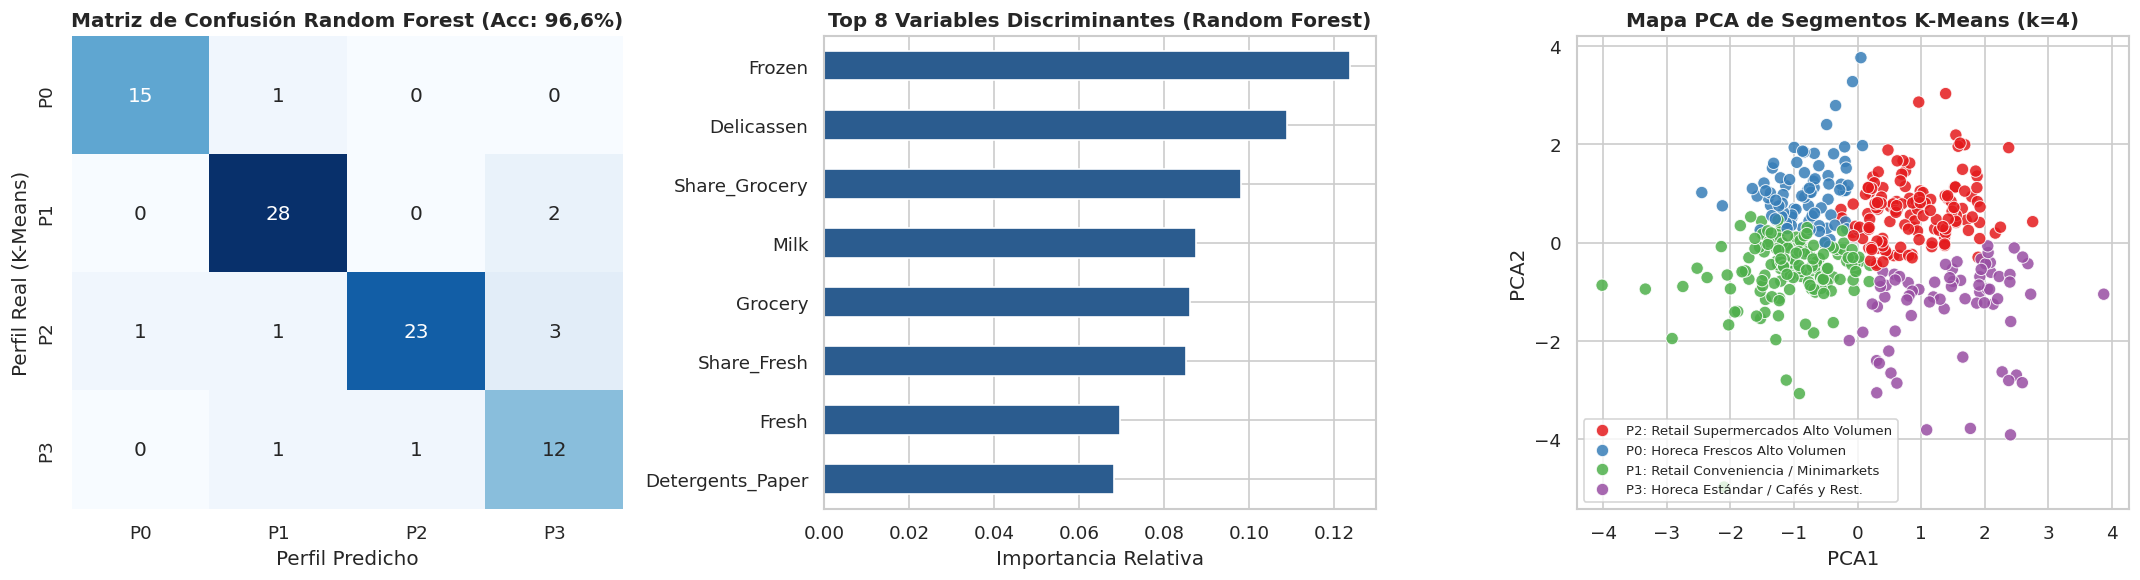

In [9]:
# Visualización integral: Matriz de Confusión + Importancia de Variables + Proyección PCA
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Matriz de Confusión (Random Forest)
cm = confusion_matrix(y_test, y_pred_rf)
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues', cbar=False,
    xticklabels=['P0', 'P1', 'P2', 'P3'],
    yticklabels=['P0', 'P1', 'P2', 'P3'],
    ax=axes[0]
)
axes[0].set_title('Matriz de Confusión Random Forest (Acc: 96,6%)', fontweight='bold')
axes[0].set_xlabel('Perfil Predicho')
axes[0].set_ylabel('Perfil Real (K-Means)')

# 2. Top 8 Variables más importantes (Random Forest)
importances = pd.Series(modelo_clasificacion.feature_importances_, index=feature_cols_clf).sort_values(ascending=True).tail(8)
importances.plot(kind='barh', color='#2b5c8f', ax=axes[1])
axes[1].set_title('Top 8 Variables Discriminantes (Random Forest)', fontweight='bold')
axes[1].set_xlabel('Importancia Relativa')

# 3. Proyección PCA 2D de los segmentos K-Means
pca = PCA(n_components=2, random_state=SEED)
coords = pca.fit_transform(X_seg)
df_prep['PCA1'] = coords[:, 0]
df_prep['PCA2'] = coords[:, 1]
sns.scatterplot(data=df_prep, x='PCA1', y='PCA2', hue='Perfil_Negocio', palette='Set1', s=55, alpha=0.85, ax=axes[2])
axes[2].set_title('Mapa PCA de Segmentos K-Means (k=4)', fontweight='bold')
axes[2].legend(loc='best', fontsize=8)

plt.tight_layout()
plt.show()

## 6. Empaquetado del Modelo (K-Means + Random Forest) y Función Operativa (Req. R.8 y R.9)

In [10]:
os.makedirs('models', exist_ok=True)
os.makedirs('data_processed', exist_ok=True)

artefacto_modelos = {
    'modelo_segmentacion_kmeans': modelo_segmentacion,
    'scaler_segmentacion': scaler_seg,
    'modelo_clasificacion_rf': modelo_clasificacion,
    'spend_cols': spend_cols,
    'feature_cols_clf': feature_cols_clf,
    'nombres_perfiles': nombres_perfiles,
    'recomendaciones': {
        0: 'Prioridad cadena de frío, despachos frecuentes de perecibles y stock dinámico en Fresh/Frozen.',
        1: 'Consolidación de rutas zonales y paquetes promocionales mixtos (Grocery + Milk).',
        2: 'Alto stock de seguridad en bodega seca, despacho paletizado y reposición programada.',
        3: 'Ventanas de entrega programadas por zona geográfica y optimización de frecuencia de reparto.'
    }
}

joblib.dump(artefacto_modelos, 'models/modelo_kmeans_rf_p04.pkl')
df_prep.to_csv('data_processed/clientes_mayoristas_segmentados.csv', index=False)

def predecir_segmento_cliente(fresh, milk, grocery, frozen, detergents_paper, delicassen):
    """
    Clasifica un nuevo cliente mayorista usando el modelo Random Forest entrenado
    sobre los segmentos descubiertos por K-Means en P04-SEG-01.
    """
    bundle = joblib.load('models/modelo_kmeans_rf_p04.pkl')
    gastos = np.array([fresh, milk, grocery, frozen, detergents_paper, delicassen], dtype=float)
    total = gastos.sum()
    shares = gastos / total

    # Vector de 13 características exactamente igual al entrenamiento
    fila_features = np.concatenate([gastos, [total], shares]).reshape(1, -1)
    df_input = pd.DataFrame(fila_features, columns=bundle['feature_cols_clf'])

    cluster_pred = int(bundle['modelo_clasificacion_rf'].predict(df_input)[0])
    probs = bundle['modelo_clasificacion_rf'].predict_proba(df_input)[0]
    prob_dict = {bundle['nombres_perfiles'][i]: f"{probs[i]*100:.1f}%" for i in range(4)}

    return {
        'Cluster_Asignado': cluster_pred,
        'Perfil_Comercial': bundle['nombres_perfiles'][cluster_pred],
        'Confianza_Prediccion': f"{probs[cluster_pred]*100:.1f}%",
        'Probabilidades_por_Perfil': prob_dict,
        'Accion_Logistica_Sugerida': bundle['recomendaciones'][cluster_pred]
    }

# Prueba funcional con 2 clientes mayoristas nuevos
print("=== PRUEBA 1: Cliente tipo Supermercado Mayorista ===")
res1 = predecir_segmento_cliente(fresh=4200, milk=14500, grocery=21800, frozen=1500, detergents_paper=8900, delicassen=1900)
for k, v in res1.items():
    print(f"  {k}: {v}")

print("\n=== PRUEBA 2: Cliente tipo Hotel / Restaurante Gran Volumen Frescos ===")
res2 = predecir_segmento_cliente(fresh=32500, milk=5400, grocery=4900, frozen=6800, detergents_paper=950, delicassen=2600)
for k, v in res2.items():
    print(f"  {k}: {v}")

=== PRUEBA 1: Cliente tipo Supermercado Mayorista ===
  Cluster_Asignado: 2
  Perfil_Comercial: P2: Retail Supermercados Alto Volumen
  Confianza_Prediccion: 99.0%
  Probabilidades_por_Perfil: {'P0: Horeca Frescos Alto Volumen': '0.0%', 'P1: Retail Conveniencia / Minimarkets': '0.0%', 'P2: Retail Supermercados Alto Volumen': '99.0%', 'P3: Horeca Estándar / Cafés y Rest.': '1.0%'}
  Accion_Logistica_Sugerida: Alto stock de seguridad en bodega seca, despacho paletizado y reposición programada.

=== PRUEBA 2: Cliente tipo Hotel / Restaurante Gran Volumen Frescos ===
  Cluster_Asignado: 0
  Perfil_Comercial: P0: Horeca Frescos Alto Volumen
  Confianza_Prediccion: 99.5%
  Probabilidades_por_Perfil: {'P0: Horeca Frescos Alto Volumen': '99.5%', 'P1: Retail Conveniencia / Minimarkets': '0.0%', 'P2: Retail Supermercados Alto Volumen': '0.5%', 'P3: Horeca Estándar / Cafés y Rest.': '0.0%'}
  Accion_Logistica_Sugerida: Prioridad cadena de frío, despachos frecuentes de perecibles y stock dinámico 